#확률적 경사 하강법

In [1]:
class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr

    def update(self, params, grads):
        for key in params.keys():
            params[key] -= self.lr * grads[key]


확률적 경사 하강법의 단점

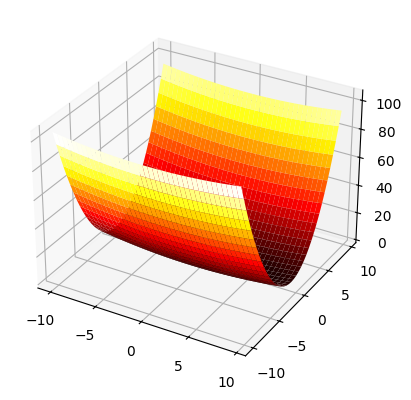

In [2]:
# 그림 6-1 f(x, y) = (1/20) * x**2 + y**2 그래프
# 3차원 참고주소: https://www.datascienceschool.net/view-notebook/6e71dbff254542d9b0a054a7c98b34ec/
%matplotlib inline
import numpy as np
import matplotlib.pylab as plt

X = np.arange(-10, 10, 0.5)
Y = np.arange(-10, 10, 0.5)
XX, YY = np.meshgrid(X, Y)
ZZ = (1 / 20) * XX**2 + YY**2


fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(XX, YY, ZZ, rstride=1, cstride=1, cmap='hot');

(-10.0, 10.0)

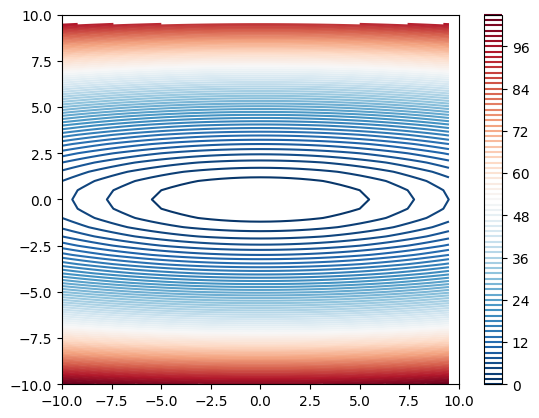

In [3]:
# 그림 6-1 f(x, y) = (1/20) * x**2 + y**2 등고선
cntr = plt.contour(XX, YY, ZZ, 100, cmap="RdBu_r")
plt.colorbar(cntr)
plt.ylim(-10, 10)
plt.xlim(-10, 10)

In [4]:
def _numerical_gradient_no_batch(f, x):
    h = 1e-4 # 0.0001
    grad = np.zeros_like(x) # x와 형상이 같은 배열을 생성

    for idx in range(x.size):
        tmp_val = x[idx]

        # f(x+h) 계산
        x[idx] = float(tmp_val) + h
        fxh1 = f(x)

        # f(x-h) 계산
        x[idx] = tmp_val - h
        fxh2 = f(x)

        grad[idx] = (fxh1 - fxh2) / (2*h)
        x[idx] = tmp_val # 값 복원

    return grad

/tmp/ipykernel_944/3246966935.py:38: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


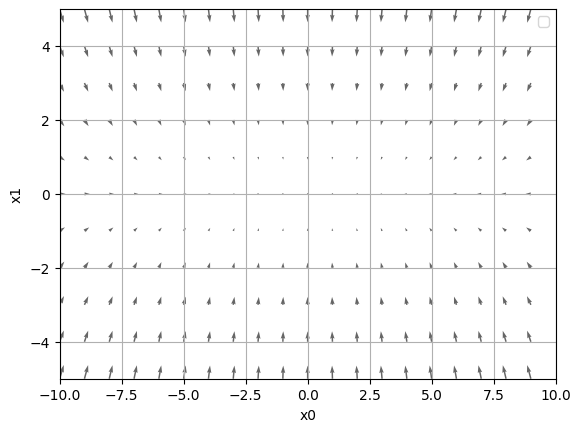

In [5]:
# 그림 6-2 f(x, y) = (1/20) * x**2 + y**2 의 기울기
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch04/gradient_2d.py 소스 참고
from mpl_toolkits.mplot3d import Axes3D

def numerical_gradient(f, X):
    if X.ndim == 1:
        return _numerical_gradient_no_batch(f, X)
    else:
        grad = np.zeros_like(X)

        for idx, x in enumerate(X):
            grad[idx] = _numerical_gradient_no_batch(f, x)

        return grad

def function_2(x):
    if x.ndim == 1:
        return np.sum(x**2)
    else:
        return np.sum(x**2, axis=1)

x0 = np.arange(-10, 10, 1)
x1 = np.arange(-10, 10, 1)
X, Y = np.meshgrid(x0, x1)

X = X.flatten()
Y = Y.flatten()

grad = numerical_gradient(function_2, np.array([(1/(20**0.5))*X, Y]) )

plt.figure()
plt.quiver(X, Y, -grad[0], -grad[1],  angles="xy",color="#666666")#,headwidth=10,scale=40,color="#444444")
plt.xlim([-10, 10])
plt.ylim([-5, 5])
plt.xlabel('x0')
plt.ylabel('x1')
plt.grid()
plt.legend()
plt.draw()
plt.show()

SGD 단점 : 비등방성(anisotropy) 함수(방향에 따라 기울기가 달라지는 함수)에서 <u>탐색경로가 비효율적.</u>



# 모멘텀



In [6]:
class Momentum:
    def __init__(self, lr=0.01, momentum=0.9):
        self.lr = lr
        self.momentum = momentum
        self.v = None

    def update(self, params, grads):
        if self.v is None:
            self.v = {}
            for key, val in params.items():
                self.v[key] = np.zeros_like(val)

        for key in params.keys():
            self.v[key] = self.momentum*self.v[key] - self.lr*grads[key]
            params[key] += self.v[key]

v: 물체의 속도

v는 초기화 때는 아무것도 담지 않고, update가 처음 호출될 때 같은 구조의 데이터를 딕셔너리 변수로 저장

# AdaGrad


In [7]:
class AdaGrad:
    def __init__(self, lr=0.01):
        self.lr = lr
        self.h = None

    def update(self, params, grads):
        if self.h is None:
            self.h = {}
            for key, val in params.items():
                self.h[key] = np.zeros_like(val)

        for key in params.keys():
            self.h[key] += grads[key] * grads[key]
            params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)

마지막 줄에서 1e-7이라는 작은 값을 더하는 부분이 0으로 나누는 사태를 막음

대부분의 딥러닝 프레임워크에서 이 값도 인수로 설정 가능

처음에는 크게 움직이지만 갱신 정도가 작아지도록 조정됨

# Adam

모멘텀: 공이 그릇을 구르는 듯한 물리 법칙에 따르는 움직임

AdaGrad: 매개변수의 원소마다 적응적으로 갱신 정도를 조정

Adam: 모멘텀과 Adagrad 기법을 융합

매개변수 공간을 효율적으로 탐색. 하이터파라미터의 '편향 보정'이 진행됨

Adam의 구현

In [8]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/common/optimizer.py 참고
class Adam:

    """Adam (http://arxiv.org/abs/1412.6980v8)"""

    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.iter = 0
        self.m = None
        self.v = None

    def update(self, params, grads):
        if self.m is None:
            self.m, self.v = {}, {}
            for key, val in params.items():
                self.m[key] = np.zeros_like(val)
                self.v[key] = np.zeros_like(val)

        self.iter += 1
        lr_t  = self.lr * np.sqrt(1.0 - self.beta2**self.iter) / (1.0 - self.beta1**self.iter)

        for key in params.keys():
            #self.m[key] = self.beta1*self.m[key] + (1-self.beta1)*grads[key]
            #self.v[key] = self.beta2*self.v[key] + (1-self.beta2)*(grads[key]**2)
            self.m[key] += (1 - self.beta1) * (grads[key] - self.m[key])
            self.v[key] += (1 - self.beta2) * (grads[key]**2 - self.v[key])

            params[key] -= lr_t * self.m[key] / (np.sqrt(self.v[key]) + 1e-7)

            #unbias_m += (1 - self.beta1) * (grads[key] - self.m[key]) # correct bias
            #unbisa_b += (1 - self.beta2) * (grads[key]*grads[key] - self.v[key]) # correct bias
            #params[key] += self.lr * unbias_m / (np.sqrt(unbisa_b) + 1e-7)

# 어느 갱신 방법을 이용할 것인가?

네 기법의 결과를 비교

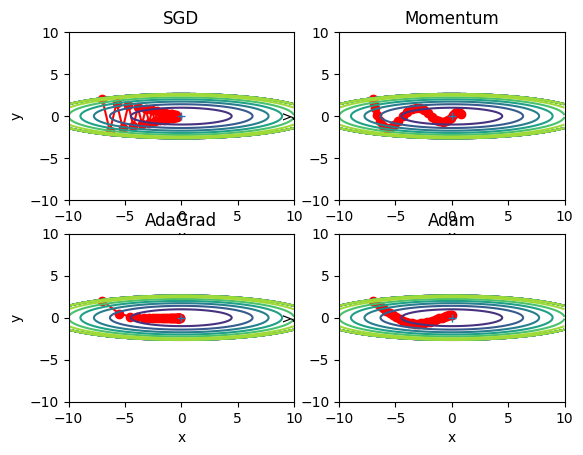

In [9]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch06/optimizer_compare_naive.py 참고
# coding: utf-8
import numpy as np
import matplotlib.pyplot as plt
from collections import OrderedDict

def f(x, y):
    return x**2 / 20.0 + y**2

def df(x, y):
    return x / 10.0, 2.0*y

init_pos = (-7.0, 2.0)
params = {}
params['x'], params['y'] = init_pos[0], init_pos[1]
grads = {}
grads['x'], grads['y'] = 0, 0


optimizers = OrderedDict()
optimizers["SGD"] = SGD(lr=0.95)
optimizers["Momentum"] = Momentum(lr=0.1)
optimizers["AdaGrad"] = AdaGrad(lr=1.5)
optimizers["Adam"] = Adam(lr=0.3)

idx = 1

for key in optimizers:
    optimizer = optimizers[key]
    x_history = []
    y_history = []
    params['x'], params['y'] = init_pos[0], init_pos[1]

    for i in range(30):
        x_history.append(params['x'])
        y_history.append(params['y'])

        grads['x'], grads['y'] = df(params['x'], params['y'])
        optimizer.update(params, grads)


    x = np.arange(-10, 10, 0.01)
    y = np.arange(-5, 5, 0.01)

    X, Y = np.meshgrid(x, y)
    Z = f(X, Y)

    # 외곽선 단순화
    mask = Z > 7
    Z[mask] = 0

    # 그래프 그리기
    plt.subplot(2, 2, idx)
    idx += 1
    plt.plot(x_history, y_history, 'o-', color="red")
    plt.contour(X, Y, Z)
    plt.ylim(-10, 10)
    plt.xlim(-10, 10)
    plt.plot(0, 0, '+')
    #colorbar()
    #spring()
    plt.title(key)
    plt.xlabel("x")
    plt.ylabel("y")

plt.show()

문제가 무엇이냐에 따라 사용할 기법이 달라짐

하이퍼 파라미터를 어떻게 설정하느냐에 따라서 결과도 바뀜

모든 문제에서 항상 뛰어난 기법은 아직 없음

이 책에서는 SGD, Adam을 많이 사용.

In [11]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [12]:
import sys
sys.path.append('/content/gdrive/MyDrive/_2026.2/인공지능/Class-Artificial-Intelligence')

In [13]:
from dataset.mnist import load_mnist
from common.util import smooth_curve
from common.multi_layer_net import MultiLayerNet

Converting train-images-idx3-ubyte.gz to NumPy Array ...
Done
Converting train-labels-idx1-ubyte.gz to NumPy Array ...
Done
Converting t10k-images-idx3-ubyte.gz to NumPy Array ...
Done
Converting t10k-labels-idx1-ubyte.gz to NumPy Array ...
Done
Creating pickle file ...
Done!
===========iteration:0===========
SGD:2.338106058681155
Momentum:2.3014577674722134
AdaGrad:2.3515357384342006
Adam:2.178794265267844
===========iteration:100===========
SGD:1.4254016679750046
Momentum:0.2633628321194291
AdaGrad:0.10295614678743836
Adam:0.24027619108976594
===========iteration:200===========
SGD:0.7025399531247983
Momentum:0.31237411759608613
AdaGrad:0.12032001385592986
Adam:0.24797019371158951
===========iteration:300===========
SGD:0.4794960155614867
Momentum:0.18933111723032778
AdaGrad:0.08600329115706828
Adam:0.11439756693553771
===========iteration:400===========
SGD:0.4186281725747362
Momentum:0.17392953332266387
AdaGrad:0.04366151623064063
Adam:0.1205859146825079
===========iteration:500===

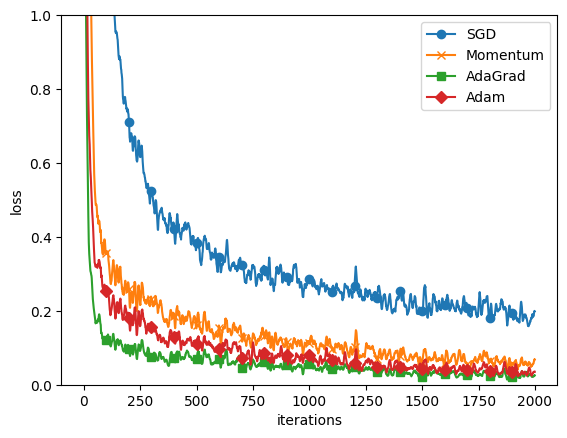

In [14]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch06/optimizer_compare_mnist.py 참고
# coding: utf-8
#import os
#import sys
#sys.path.append(os.pardir)  # 부모 디렉터리의 파일을 가져올 수 있도록 설정

import matplotlib.pyplot as plt

#from common.optimizer import *

# 0. MNIST 데이터 읽기==========
(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True)

train_size = x_train.shape[0]
batch_size = 128
max_iterations = 2000

# 1. 실험용 설정==========
optimizers = {}
optimizers['SGD'] = SGD()
optimizers['Momentum'] = Momentum()
optimizers['AdaGrad'] = AdaGrad()
optimizers['Adam'] = Adam()
#optimizers['RMSprop'] = RMSprop()

networks = {}
train_loss = {}
for key in optimizers.keys():
    networks[key] = MultiLayerNet(
        input_size=784, hidden_size_list=[100, 100, 100, 100],
        output_size=10)
    train_loss[key] = []

# 2. 훈련 시작==========
for i in range(max_iterations):
    batch_mask = np.random.choice(train_size, batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    for key in optimizers.keys():
        grads = networks[key].gradient(x_batch, t_batch)
        optimizers[key].update(networks[key].params, grads)

        loss = networks[key].loss(x_batch, t_batch)
        train_loss[key].append(loss)

    if i % 100 == 0:
        print( "===========" + "iteration:" + str(i) + "===========")
        for key in optimizers.keys():
            loss = networks[key].loss(x_batch, t_batch)
            print(key + ":" + str(loss))

# 3. 그래프 그리기==========
markers = {"SGD": "o", "Momentum": "x", "AdaGrad": "s", "Adam": "D"}
x = np.arange(max_iterations)
for key in optimizers.keys():
    plt.plot(x, smooth_curve(train_loss[key]), marker=markers[key], markevery=100, label=key)
plt.xlabel("iterations")
plt.ylabel("loss")
plt.ylim(0, 1)
plt.legend()
plt.show()

각 층이 100개의 뉴런으로 구성된 5층 신경망에서 ReLU를 활성화 함수로 사용해 측정

하이퍼파라미터인 학습률과 신경망의 구조(층 깊이 등)에 따라 결과가 달라짐

일반적으로 SGD보다 다른 세 기법이 빠르게 학습하고, 때로는 최종 정확도도 높음

## 가중치의 초기값

가중치의 초기값을 무엇으로 설정하느냐가 신경망 학습의 성패를 가름

# 은닉층의 활성화값 분포

가중치의 초기값에 따라 은닉층 활성화 값들이 어떻게 변화는지 실험

각 층의 활성화값 분포를 히스토그램으로 그림

In [15]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch06/weight_init_activation_histogram.py 참고
# coding: utf-8
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def ReLU(x):
    return np.maximum(0, x)

def tanh(x):
    return np.tanh(x)

input_data = np.random.randn(1000, 100)  # 1000개의 데이터
node_num = 100  # 각 은닉층의 노드(뉴런) 수
hidden_layer_size = 5  # 은닉층이 5개
activations = {}  # 이곳에 활성화 결과를 저장

x = input_data

def get_activation(hidden_layer_size, x, w, a_func=sigmoid):
    for i in range(hidden_layer_size):
        if i != 0:
            x = activations[i-1]

        a = np.dot(x, w)

        # 활성화 함수도 바꿔가며 실험해보자！
        z = a_func(a)
        # z = ReLU(a)
        # z = tanh(a)

        activations[i] = z
    return activations

# 초깃값을 다양하게 바꿔가며 실험해보자！
w = np.random.randn(node_num, node_num) * 1
# w = np.random.randn(node_num, node_num) * 0.01
# w = np.random.randn(node_num, node_num) * np.sqrt(1.0 / node_num)
# w = np.random.randn(node_num, node_num) * np.sqrt(2.0 / node_num)

z = sigmoid
# z = ReLU
# z = tanh

activations = get_activation(hidden_layer_size, x, w, z)

표준편차가 1인 정규분포의 활성화값들의 분포

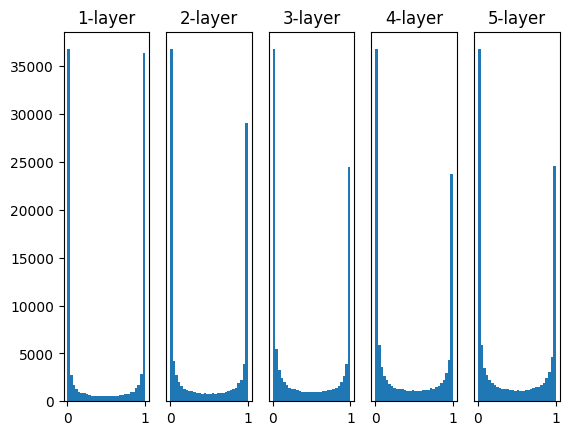

In [16]:
# 히스토그램 그리기
def get_histogram(activations):
    for i, a in activations.items():
        plt.subplot(1, len(activations), i+1)
        plt.title(str(i+1) + "-layer")
        if i != 0: plt.yticks([], [])
        # plt.xlim(0.1, 1)
        # plt.ylim(0, 7000)
        plt.hist(a.flatten(), 30, range=(0,1))
    plt.show()

get_histogram(activations)

기울기 소실(gradient vanishing)

데이터가 0과 1에 치우쳐 분포하게 되면 역전파 기울기 값이 점점 작아지다 사라짐

가중치의 표준편차를 0.01로 변경

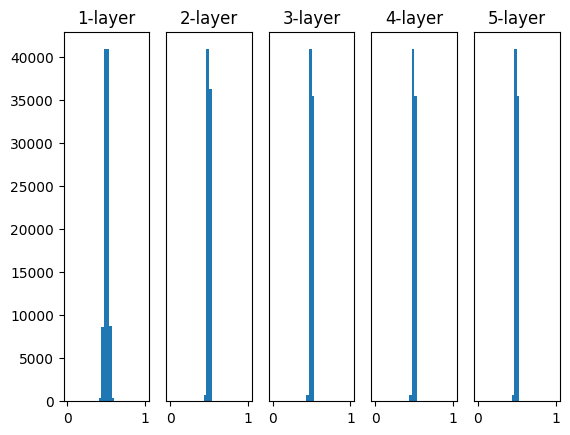

In [17]:
w = np.random.randn(node_num, node_num) * 0.01
activations = get_activation(hidden_layer_size, x, w, z)
get_histogram(activations)

0.5 부근에 집중. 활성화값들이 치우쳤다는 것은 표현력 관점에서 큰 문제

표현력을 제한: 예를 들어 뉴런 100개가 거의 같은 값을 출력한다면 뉴런 1개짜리와 별반 다를게 없음

<u>Xavier 초기값</u>

앞 계층의 노드가 n개라면 표준편차가 1 / np.sqrt(n)인 정규분포를 사용

사비에르 논문은 앞 층의 노드 수 외에 다음 출력 노드 수도 고려한 설정 값 제안.

카페 등의 프레임워크는 앞층의 입력 노드만으로 계산하도록 단순화.

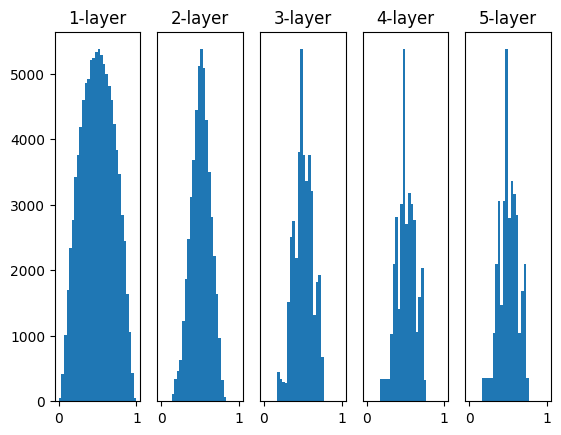

In [18]:
# Xavier 초기값
w = np.random.randn(node_num, node_num) * np.sqrt(1.0 / node_num)
activations = get_activation(hidden_layer_size, x, w, z)
get_histogram(activations)

층이 깊어지면서 형태가 다소 일그러지지만, 넓게 분포됨

시그모이드 함수의 표현력도 제한받지 않고 학습이 효율적으로 이뤄질 것

# ReLU를 사용할 때의 가중치 초기값

sigmoid, tanh는 좌우 대칭이라 Xavier 초기값이 적당

He 초기값

ReLu에 특화된 초기값.

앞 계층의 노드가 n일 때 표준편차가 2 / np.sqrt(n)인 정규분포를 사용

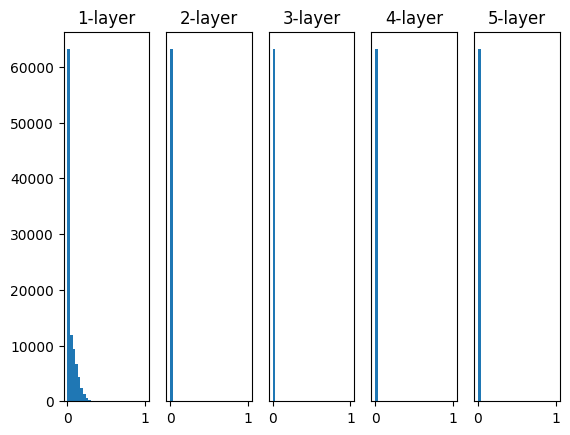

In [19]:
# 표준편차가 0.01인 정규분포를 가중치 초기값으로 사용한 경우
w = np.random.randn(node_num, node_num) * 0.01
z = ReLU
activations = get_activation(hidden_layer_size, x, w, z)
get_histogram(activations)

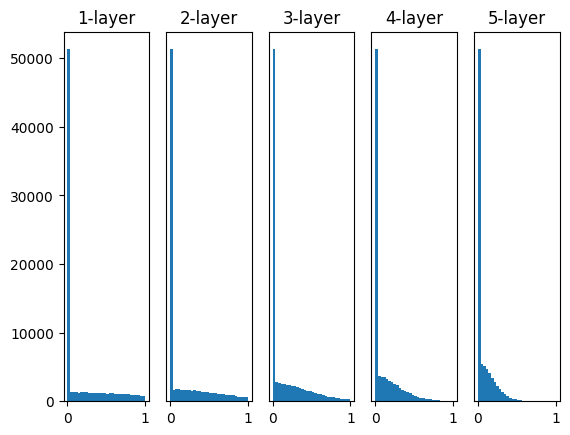

In [20]:
# Xavier 초기값을 사용한 경우
w = np.random.randn(node_num, node_num) * np.sqrt(1.0 / node_num)
activations = get_activation(hidden_layer_size, x, w, z)
get_histogram(activations)

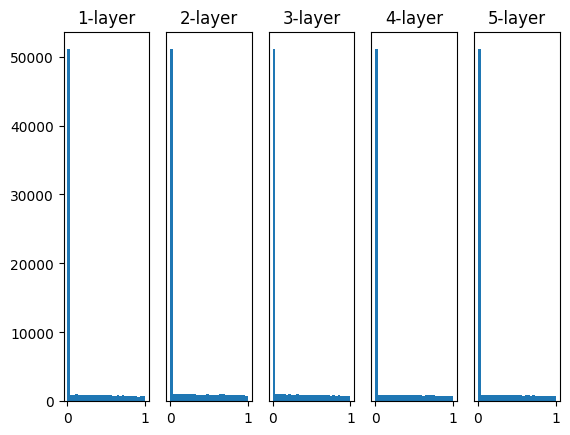

In [21]:
# He 초기값을 사용한 경우
w = np.random.randn(node_num, node_num) * np.sqrt(2.0 / node_num)
activations = get_activation(hidden_layer_size, x, w, z)
get_histogram(activations)

std = 0.01일 때

각 층의 활성화 값들이 아주 작은 값들. 역전파의 가중치의 기울기 역시 작아짐. 실제로 학습이 거의 이뤄지지 않음

Xavier 초기값일 때

층이 깊어지면 활성화값들이 치우침. 학습할 때 '기울기 소실'문제.

He 초기값일 때

모든 층에서 균일하게 분포.

실험결과

활성화 함수로 ReLU를 사용할 때 He 초기값.

활성화 함수로 sigmoid, tanh 등 S자 모양 곡선일 때는 Xavier 초기값.

# MNIST 데이터셋으로 본 가중치 초기값

실제 데이터로 가중치의 초기값을 주는 방법이 신경망 학습에 얼마나 영향을 주는지 그래프

In [22]:
from google.colab import drive
drive.mount('/content/gdrive/')

Drive already mounted at /content/gdrive/; to attempt to forcibly remount, call drive.mount("/content/gdrive/", force_remount=True).


In [23]:
import sys
sys.path.append('/content/gdrive/MyDrive/_2026.2/인공지능/Class-Artificial-Intelligence')

#https://github.com/WegraLee/deep-learning-from-scratch

from dataset.mnist import load_mnist
from common.util import smooth_curve
from common.multi_layer_net import MultiLayerNet

===========iteration:0===========
std=0.01:2.302533860762872
Xavier:2.3009279442177353
He:2.417954635822785
===========iteration:100===========
std=0.01:2.3023958725681144
Xavier:2.2429521722926573
He:1.5919299308102346
===========iteration:200===========
std=0.01:2.3005024350926666
Xavier:2.0531346777277846
He:0.6951384825591059
===========iteration:300===========
std=0.01:2.301530118133737
Xavier:1.7175464770298996
He:0.5548834290628604
===========iteration:400===========
std=0.01:2.301690662189293
Xavier:1.1312622359523536
He:0.3538592225537057
===========iteration:500===========
std=0.01:2.3014927709987996
Xavier:0.8067682477458675
He:0.4409552493318938
===========iteration:600===========
std=0.01:2.300615549977877
Xavier:0.7305754523106542
He:0.3655187726283503
===========iteration:700===========
std=0.01:2.299889070940853
Xavier:0.5240354751362389
He:0.3283231936253931
===========iteration:800===========
std=0.01:2.3046156846744426
Xavier:0.49058373874541744
He:0.3236371928606756

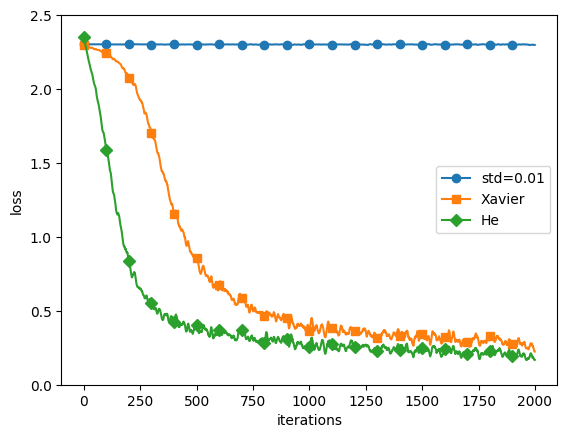

In [24]:
import numpy as np
import matplotlib.pyplot as plt

#from common.optimizer import SGD


# 0. MNIST 데이터 읽기==========
(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True)

train_size = x_train.shape[0]
batch_size = 128
max_iterations = 2000


# 1. 실험용 설정==========
weight_init_types = {'std=0.01': 0.01, 'Xavier': 'sigmoid', 'He': 'relu'}
optimizer = SGD(lr=0.01)

networks = {}
train_loss = {}
for key, weight_type in weight_init_types.items():
    networks[key] = MultiLayerNet(input_size=784, hidden_size_list=[100, 100, 100, 100],
                                  output_size=10, weight_init_std=weight_type)
    train_loss[key] = []


# 2. 훈련 시작==========
for i in range(max_iterations):
    batch_mask = np.random.choice(train_size, batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    for key in weight_init_types.keys():
        grads = networks[key].gradient(x_batch, t_batch)
        optimizer.update(networks[key].params, grads)

        loss = networks[key].loss(x_batch, t_batch)
        train_loss[key].append(loss)

    if i % 100 == 0:
        print("===========" + "iteration:" + str(i) + "===========")
        for key in weight_init_types.keys():
            loss = networks[key].loss(x_batch, t_batch)
            print(key + ":" + str(loss))


# 3. 그래프 그리기==========
markers = {'std=0.01': 'o', 'Xavier': 's', 'He': 'D'}
x = np.arange(max_iterations)
for key in weight_init_types.keys():
    plt.plot(x, smooth_curve(train_loss[key]), marker=markers[key], markevery=100, label=key)
plt.xlabel("iterations")
plt.ylabel("loss")
plt.ylim(0, 2.5)
plt.legend()
plt.show()

층별 뉴런 수가 100개인 5층 신경망에서 활성화 함수로 ReLu를 사용.

표준편차가 0.01일 때 학습이 전혀 이뤄지지 않음

Xaview, He 초기값은 학습이 순조로움. He 초기값이 학습진도가 빠름.

# 배치 정규화의 효과

============== 1/1.0 ==============


/content/gdrive/MyDrive/_2026.2/인공지능/Class-Artificial-Intelligence/common/layers.py:57: RuntimeWarning: overflow encountered in dot
  out = np.dot(self.x, self.W) + self.b
/content/gdrive/MyDrive/_2026.2/인공지능/Class-Artificial-Intelligence/common/functions.py:32: RuntimeWarning: invalid value encountered in subtract
  x = x - np.max(x, axis=-1, keepdims=True) # 오버플로 대책
/tmp/ipykernel_944/1415824360.py:83: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='lower right')
/content/gdrive/MyDrive/_2026.2/인공지능/Class-Artificial-Intelligence/common/multi_layer_net_extend.py:105: RuntimeWarning: overflow encountered in square
  weight_decay += 0.5 * self.weight_decay_lambda * np.sum(W**2)
/content/gdrive/MyDrive/_2026.2/인공지능/Class-Artificial-Intelligence/common/multi_layer_net_extend.py:105: RuntimeWarning: invalid value encountered

============== 2/0.5411695265464637 ==============
============== 3/0.2928644564625237 ==============
============== 4/0.15848931924611134 ==============
============== 5/0.08576958985908942 ==============
============== 6/0.046415888336127795 ==============
============== 7/0.025118864315095794 ==============
============== 8/0.013593563908785255 ==============
============== 9/0.007356422544596414 ==============
============== 10/0.003981071705534973 ==============
============== 11/0.0021544346900318843 ==============
============== 12/0.0011659144011798323 ==============
============== 13/0.000630957344480193 ==============
============== 14/0.0003414548873833601 ==============
============== 15/0.00018478497974222906 ==============
============== 16/0.0001 ==============


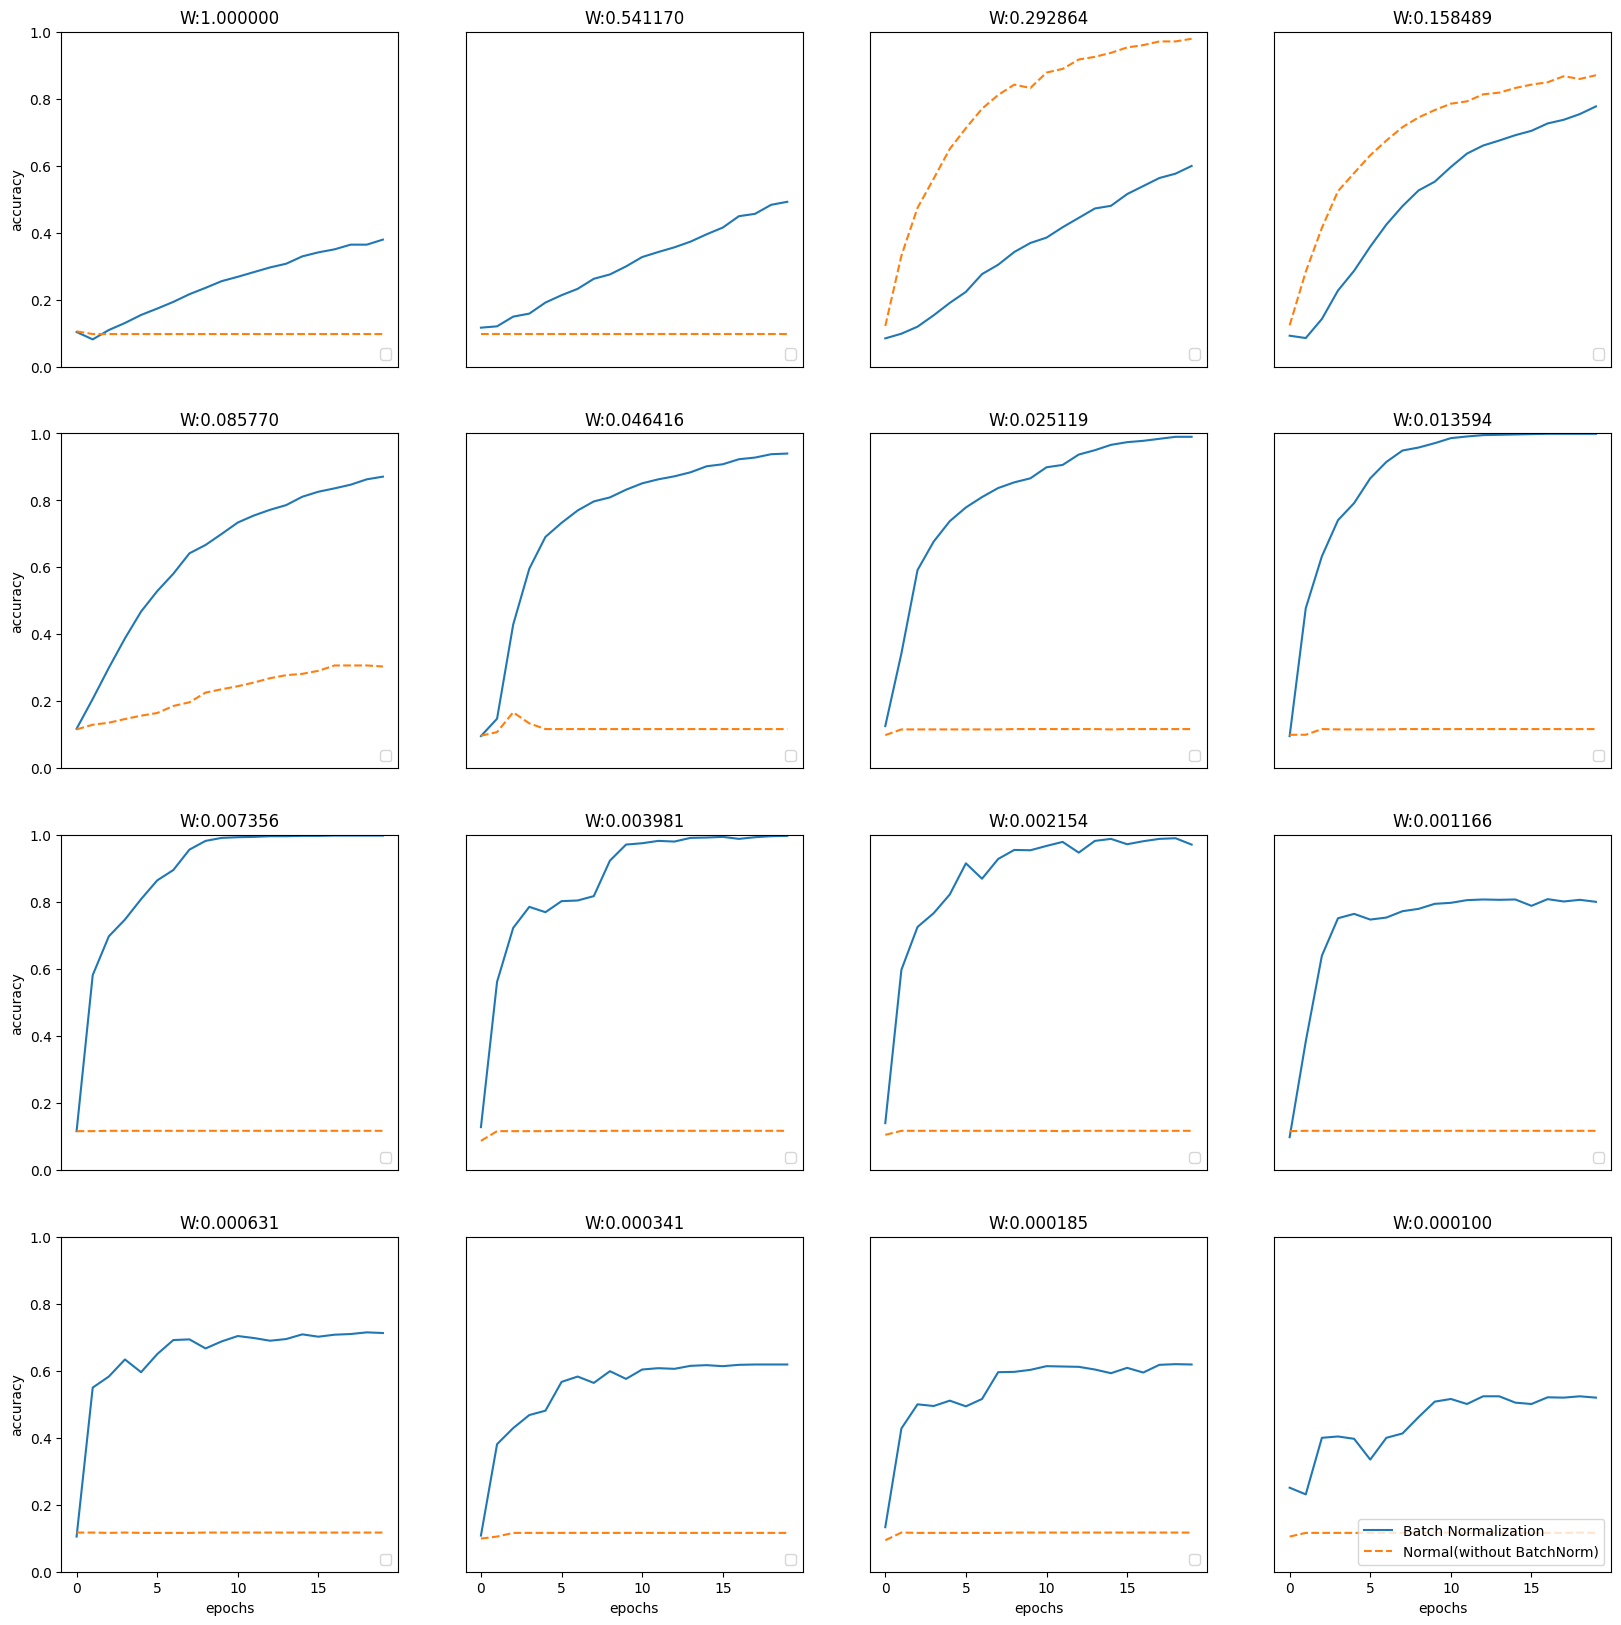

In [25]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch06/batch_norm_test.py 참고
import numpy as np
import matplotlib.pyplot as plt
from dataset.mnist import load_mnist
from common.multi_layer_net_extend import MultiLayerNetExtend
#from common.optimizer import SGD, Adam

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True)

# 학습 데이터를 줄임
x_train = x_train[:1000]
t_train = t_train[:1000]

max_epochs = 20
train_size = x_train.shape[0]
batch_size = 100
learning_rate = 0.01


def __train(weight_init_std):
    bn_network = MultiLayerNetExtend(input_size=784, hidden_size_list=[100, 100, 100, 100, 100], output_size=10,
                                    weight_init_std=weight_init_std, use_batchnorm=True)
    network = MultiLayerNetExtend(input_size=784, hidden_size_list=[100, 100, 100, 100, 100], output_size=10,
                                weight_init_std=weight_init_std)
    optimizer = SGD(lr=learning_rate)

    train_acc_list = []
    bn_train_acc_list = []

    iter_per_epoch = max(train_size / batch_size, 1)
    epoch_cnt = 0

    for i in range(1000000000):
        batch_mask = np.random.choice(train_size, batch_size)
        x_batch = x_train[batch_mask]
        t_batch = t_train[batch_mask]

        for _network in (bn_network, network):
            grads = _network.gradient(x_batch, t_batch)
            optimizer.update(_network.params, grads)

        if i % iter_per_epoch == 0:
            train_acc = network.accuracy(x_train, t_train)
            bn_train_acc = bn_network.accuracy(x_train, t_train)
            train_acc_list.append(train_acc)
            bn_train_acc_list.append(bn_train_acc)

            #print("epoch:" + str(epoch_cnt) + " | " + str(train_acc) + " - " + str(bn_train_acc))

            epoch_cnt += 1
            if epoch_cnt >= max_epochs:
                break

    return train_acc_list, bn_train_acc_list


# 그래프 그리기==========
weight_scale_list = np.logspace(0, -4, num=16)
x = np.arange(max_epochs)
fig = plt.figure(figsize=(20, 20))
for i, w in enumerate(weight_scale_list):
    print( "============== " + str(i+1) + "/" +str(w)+ " ==============")
    train_acc_list, bn_train_acc_list = __train(w)

    plt.subplot(4,4,i+1)
    plt.title("W:{:.6f}".format(w))
    if i == 15:
        plt.plot(x, bn_train_acc_list, label='Batch Normalization', markevery=2)
        plt.plot(x, train_acc_list, linestyle = "--", label='Normal(without BatchNorm)', markevery=2)
    else:
        plt.plot(x, bn_train_acc_list, markevery=2)
        plt.plot(x, train_acc_list, linestyle="--", markevery=2)

    plt.ylim(0, 1.0)
    if i % 4:
        plt.yticks([])
    else:
        plt.ylabel("accuracy")
    if i < 12:
        plt.xticks([])
    else:
        plt.xlabel("epochs")
    plt.legend(loc='lower right')

plt.show()

# 오버피팅

In [26]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch06/overfit_weight_decay.py 참고
from dataset.mnist import load_mnist

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True)
# 오버피팅을 재현하기 위해 학습 데이터 수를 줄임
x_train = x_train[:300]
t_train = t_train[:300]

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from common.multi_layer_net import MultiLayerNet
#from common.optimizer import SGD

# weight decay（가중치 감쇠） 설정 =======================
weight_decay_lambda = 0 # weight decay를 사용하지 않을 경우
#weight_decay_lambda = 0.1
# ====================================================

network = MultiLayerNet(input_size=784, hidden_size_list=[100, 100, 100, 100, 100, 100], output_size=10,
                        weight_decay_lambda=weight_decay_lambda)
optimizer = SGD(lr=0.01) # 학습률이 0.01인 SGD로 매개변수 갱신

max_epochs = 201
train_size = x_train.shape[0]
batch_size = 100

train_loss_list = []
train_acc_list = []
test_acc_list = []

iter_per_epoch = max(train_size / batch_size, 1)
epoch_cnt = 0

for i in range(1000000000):
    batch_mask = np.random.choice(train_size, batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    grads = network.gradient(x_batch, t_batch)
    optimizer.update(network.params, grads)

    if i % iter_per_epoch == 0:
        train_acc = network.accuracy(x_train, t_train)
        test_acc = network.accuracy(x_test, t_test)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)

        print("epoch:" + str(epoch_cnt) + ", train acc:" + str(train_acc) + ", test acc:" + str(test_acc))

        epoch_cnt += 1
        if epoch_cnt >= max_epochs:
            break

epoch:0, train acc:0.12333333333333334, test acc:0.0993
epoch:1, train acc:0.13333333333333333, test acc:0.1132
epoch:2, train acc:0.16666666666666666, test acc:0.1269
epoch:3, train acc:0.20333333333333334, test acc:0.1362
epoch:4, train acc:0.24, test acc:0.1598
epoch:5, train acc:0.27, test acc:0.1737
epoch:6, train acc:0.27, test acc:0.1858
epoch:7, train acc:0.2833333333333333, test acc:0.1968
epoch:8, train acc:0.30333333333333334, test acc:0.2233
epoch:9, train acc:0.3, test acc:0.2332
epoch:10, train acc:0.35333333333333333, test acc:0.2524
epoch:11, train acc:0.35, test acc:0.2556
epoch:12, train acc:0.36666666666666664, test acc:0.274
epoch:13, train acc:0.37333333333333335, test acc:0.2847
epoch:14, train acc:0.4166666666666667, test acc:0.3103
epoch:15, train acc:0.43333333333333335, test acc:0.3181
epoch:16, train acc:0.4166666666666667, test acc:0.3202
epoch:17, train acc:0.44, test acc:0.3339
epoch:18, train acc:0.4666666666666667, test acc:0.3446
epoch:19, train acc:0.5

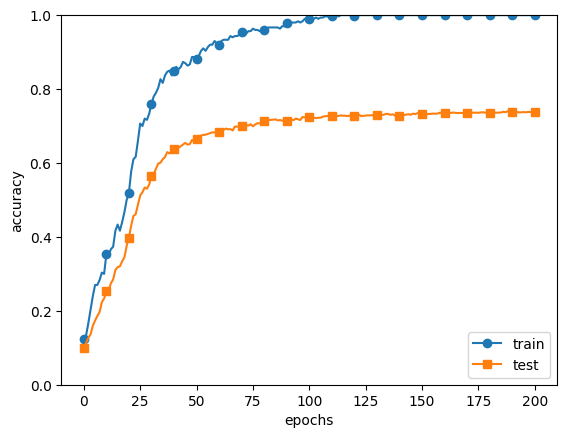

In [28]:
# 그래프 그리기==========
markers = {'train': 'o', 'test': 's'}
x = np.arange(max_epochs)
plt.plot(x, train_acc_list, marker='o', label='train', markevery=10)
plt.plot(x, test_acc_list, marker='s', label='test', markevery=10)
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.legend(loc='lower right')
plt.show()

# 가중치 감소

epoch:0, train acc:0.24666666666666667, test acc:0.2055
epoch:1, train acc:0.25, test acc:0.2182
epoch:2, train acc:0.2966666666666667, test acc:0.2384
epoch:3, train acc:0.30666666666666664, test acc:0.254
epoch:4, train acc:0.32, test acc:0.2608
epoch:5, train acc:0.33666666666666667, test acc:0.2688
epoch:6, train acc:0.37333333333333335, test acc:0.2914
epoch:7, train acc:0.38, test acc:0.296
epoch:8, train acc:0.39, test acc:0.305
epoch:9, train acc:0.4066666666666667, test acc:0.3215
epoch:10, train acc:0.41, test acc:0.3243
epoch:11, train acc:0.4033333333333333, test acc:0.3295
epoch:12, train acc:0.41333333333333333, test acc:0.3321
epoch:13, train acc:0.42333333333333334, test acc:0.3361
epoch:14, train acc:0.43, test acc:0.3361
epoch:15, train acc:0.44666666666666666, test acc:0.3496
epoch:16, train acc:0.4633333333333333, test acc:0.3572
epoch:17, train acc:0.47333333333333333, test acc:0.3659
epoch:18, train acc:0.4766666666666667, test acc:0.372
epoch:19, train acc:0.48, 

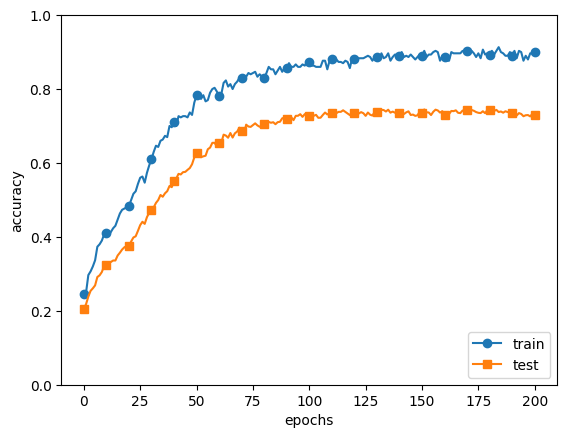

In [29]:
# weight decay（가중치 감쇠） 설정 =======================
#weight_decay_lambda = 0 # weight decay를 사용하지 않을 경우
weight_decay_lambda = 0.1
# ====================================================

network = MultiLayerNet(input_size=784, hidden_size_list=[100, 100, 100, 100, 100, 100], output_size=10,
                        weight_decay_lambda=weight_decay_lambda)
optimizer = SGD(lr=0.01) # 학습률이 0.01인 SGD로 매개변수 갱신

max_epochs = 201
train_size = x_train.shape[0]
batch_size = 100

train_loss_list = []
train_acc_list = []
test_acc_list = []

iter_per_epoch = max(train_size / batch_size, 1)
epoch_cnt = 0

for i in range(1000000000):
    batch_mask = np.random.choice(train_size, batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    grads = network.gradient(x_batch, t_batch)
    optimizer.update(network.params, grads)

    if i % iter_per_epoch == 0:
        train_acc = network.accuracy(x_train, t_train)
        test_acc = network.accuracy(x_test, t_test)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)

        print("epoch:" + str(epoch_cnt) + ", train acc:" + str(train_acc) + ", test acc:" + str(test_acc))

        epoch_cnt += 1
        if epoch_cnt >= max_epochs:
            break

# 그래프 그리기==========
markers = {'train': 'o', 'test': 's'}
x = np.arange(max_epochs)
plt.plot(x, train_acc_list, marker='o', label='train', markevery=10)
plt.plot(x, test_acc_list, marker='s', label='test', markevery=10)
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.legend(loc='lower right')
plt.show()

# 드롭아웃

In [30]:
class Dropout:
    def __init__(self, dropout_ratio=0.5):
        self.dropout_ratio = dropout_ratio
        self.mask = None

    def forward(self, x, train_flg=True):
        if train_flg:
            self.mask = np.random.rand(*x.shape) > self.dropout_ratio
            return x * self.mask
        else:
            return x * (1.0 - self.dropout_ratio)

    def backward(self, dout):
        return dout * self.mask

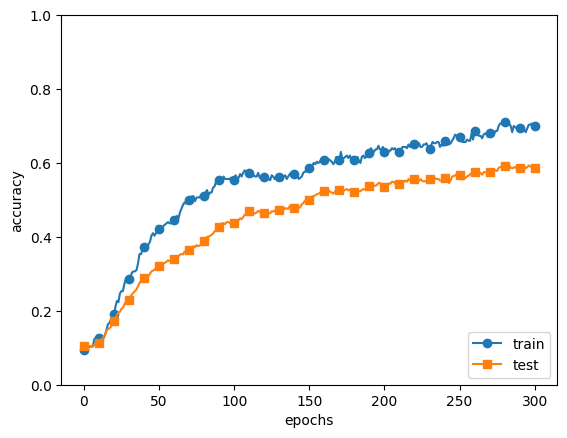

In [33]:
# coding: utf-8
import numpy as np
import matplotlib.pyplot as plt
from dataset.mnist import load_mnist
from common.multi_layer_net_extend import MultiLayerNetExtend
from common.trainer import Trainer

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True)

# 오버피팅을 재현하기 위해 학습 데이터 수를 줄임
x_train = x_train[:300]
t_train = t_train[:300]

# 드롭아웃 사용 유무와 비울 설정 ========================
use_dropout = True  # 드롭아웃을 쓰지 않을 때는 False
dropout_ratio = 0.2
# ====================================================

network = MultiLayerNetExtend(input_size=784, hidden_size_list=[100, 100, 100, 100, 100, 100],
                              output_size=10, use_dropout=use_dropout, dropout_ration=dropout_ratio)
trainer = Trainer(network, x_train, t_train, x_test, t_test,
                  epochs=301, mini_batch_size=100,
                  optimizer='sgd', optimizer_param={'lr': 0.01}, verbose=False)
trainer.train()

train_acc_list, test_acc_list = trainer.train_acc_list, trainer.test_acc_list

# 그래프 그리기==========
markers = {'train': 'o', 'test': 's'}
x = np.arange(len(train_acc_list))
plt.plot(x, train_acc_list, marker='o', label='train', markevery=10)
plt.plot(x, test_acc_list, marker='s', label='test', markevery=10)
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.legend(loc='lower right')
plt.show()

# 검증 데이터

In [34]:
from dataset.mnist import load_mnist
from common.util import shuffle_dataset

(x_train, t_train), (x_test, t_test) = load_mnist()

# 훈련 데이터를 뒤섞는다.
x_train, t_train = shuffle_dataset(x_train, t_train)

# 20%를 검증 데이터로 분할
validation_rate = 0.20
validation_num = int(x_train.shape[0] * validation_rate)

x_val = x_train[:validation_num]
t_val = t_train[:validation_num]
x_train = x_train[validation_num:]
t_train = t_train[validation_num:]

# 하이퍼파라미터 최적화

In [35]:
weight_decay = 10**np.random.uniform(-8,-4)
lr = 10**np.random.uniform(-6,-2)

val acc:0.11 | lr:0.0004155282858434928, weight decay:3.005184774430111e-07
val acc:0.15 | lr:0.00021382204939772965, weight decay:1.0265380131727845e-05
val acc:0.68 | lr:0.0061298910531733695, weight decay:2.339626963524539e-07
val acc:0.42 | lr:0.0017906358819570643, weight decay:1.3319559082638008e-07
val acc:0.07 | lr:1.1511287478925153e-06, weight decay:1.976618001706497e-08
val acc:0.1 | lr:0.00010629435014491856, weight decay:1.47988951554605e-07
val acc:0.05 | lr:1.3802042683356753e-06, weight decay:6.06429111927359e-06
val acc:0.07 | lr:2.446408064177532e-06, weight decay:2.9709567184619874e-05
val acc:0.17 | lr:0.0006533349433472464, weight decay:9.785028018979512e-05
val acc:0.25 | lr:0.002180321864860797, weight decay:9.14951865254062e-05
val acc:0.16 | lr:5.362293857142462e-05, weight decay:5.50395380354187e-06
val acc:0.15 | lr:3.3192411226313e-05, weight decay:2.0450634353422176e-05
val acc:0.04 | lr:3.608657583664295e-06, weight decay:1.8114144535050317e-08
val acc:0.0

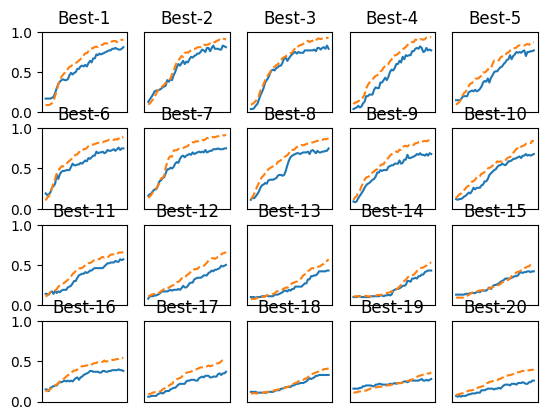

In [36]:
# https://github.com/WegraLee/deep-learning-from-scratch/blob/master/ch06/hyperparameter_optimization.py 참고
import numpy as np
import matplotlib.pyplot as plt
from dataset.mnist import load_mnist
from common.multi_layer_net import MultiLayerNet
from common.util import shuffle_dataset
from common.trainer import Trainer

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True)

# 결과를 빠르게 얻기 위해 훈련 데이터를 줄임
x_train = x_train[:500]
t_train = t_train[:500]

# 20%를 검증 데이터로 분할
validation_rate = 0.20
validation_num = int(x_train.shape[0] * validation_rate)
x_train, t_train = shuffle_dataset(x_train, t_train)
x_val = x_train[:validation_num]
t_val = t_train[:validation_num]
x_train = x_train[validation_num:]
t_train = t_train[validation_num:]


def __train(lr, weight_decay, epocs=50):
    network = MultiLayerNet(input_size=784, hidden_size_list=[100, 100, 100, 100, 100, 100],
                            output_size=10, weight_decay_lambda=weight_decay)
    trainer = Trainer(network, x_train, t_train, x_val, t_val,
                      epochs=epocs, mini_batch_size=100,
                      optimizer='sgd', optimizer_param={'lr': lr}, verbose=False)
    trainer.train()

    return trainer.test_acc_list, trainer.train_acc_list


# 하이퍼파라미터 무작위 탐색======================================
optimization_trial = 100
results_val = {}
results_train = {}
for _ in range(optimization_trial):
    # 탐색한 하이퍼파라미터의 범위 지정===============
    weight_decay = 10 ** np.random.uniform(-8, -4)
    lr = 10 ** np.random.uniform(-6, -2)
    # ================================================

    val_acc_list, train_acc_list = __train(lr, weight_decay)
    print("val acc:" + str(val_acc_list[-1]) + " | lr:" + str(lr) + ", weight decay:" + str(weight_decay))
    key = "lr:" + str(lr) + ", weight decay:" + str(weight_decay)
    results_val[key] = val_acc_list
    results_train[key] = train_acc_list

# 그래프 그리기========================================================
print("=========== Hyper-Parameter Optimization Result ===========")
graph_draw_num = 20
col_num = 5
row_num = int(np.ceil(graph_draw_num / col_num))
i = 0

for key, val_acc_list in sorted(results_val.items(), key=lambda x:x[1][-1], reverse=True):
    print("Best-" + str(i+1) + "(val acc:" + str(val_acc_list[-1]) + ") | " + key)

    plt.subplot(row_num, col_num, i+1)
    plt.title("Best-" + str(i+1))
    plt.ylim(0.0, 1.0)
    if i % 5: plt.yticks([])
    plt.xticks([])
    x = np.arange(len(val_acc_list))
    plt.plot(x, val_acc_list)
    plt.plot(x, results_train[key], "--")
    i += 1

    if i >= graph_draw_num:
        break

plt.show()